# 06: Route Clustering Feature Table
**Milestone 2: Week 4 — Step 13**

This notebook builds and evaluates the route-level feature table for clustering the 41 Manhattan routes:
- Computed strictly from **typical weekdays in the training period** (4 January to 31 May)
- Candidate metrics: weekday volume (log), weekend-to-weekday ratio, peak shares, peak/offpeak efficiency, length, speed, variability, coverage
- Multicollinearity pruning: drop one of each pair with $|r| > 0.85$
- Feature standardization using `StandardScaler`

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.eda_utils import typical_days, DAY_TYPE_COLORS, calc_period_ratio, calc_cv

DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

matched = pd.read_parquet(DATA / "matched_hourly.parquet")
profiles = pd.read_parquet(DATA / "route_profiles.parquet")
print(f"Loaded matched hourly: {len(matched):,} rows (41 routes)")
print(f"Loaded route profiles: {len(profiles)} routes")


Loaded matched hourly: 233,227 rows (41 routes)
Loaded route profiles: 41 routes


## Step 13.1: Candidate Features & Multicollinearity Pruning
With 41 routes, models require a concise set of 8 to 10 features without redundant collinearity ($|r| > 0.85$).

Correlation Matrix for Candidate Route Metrics:


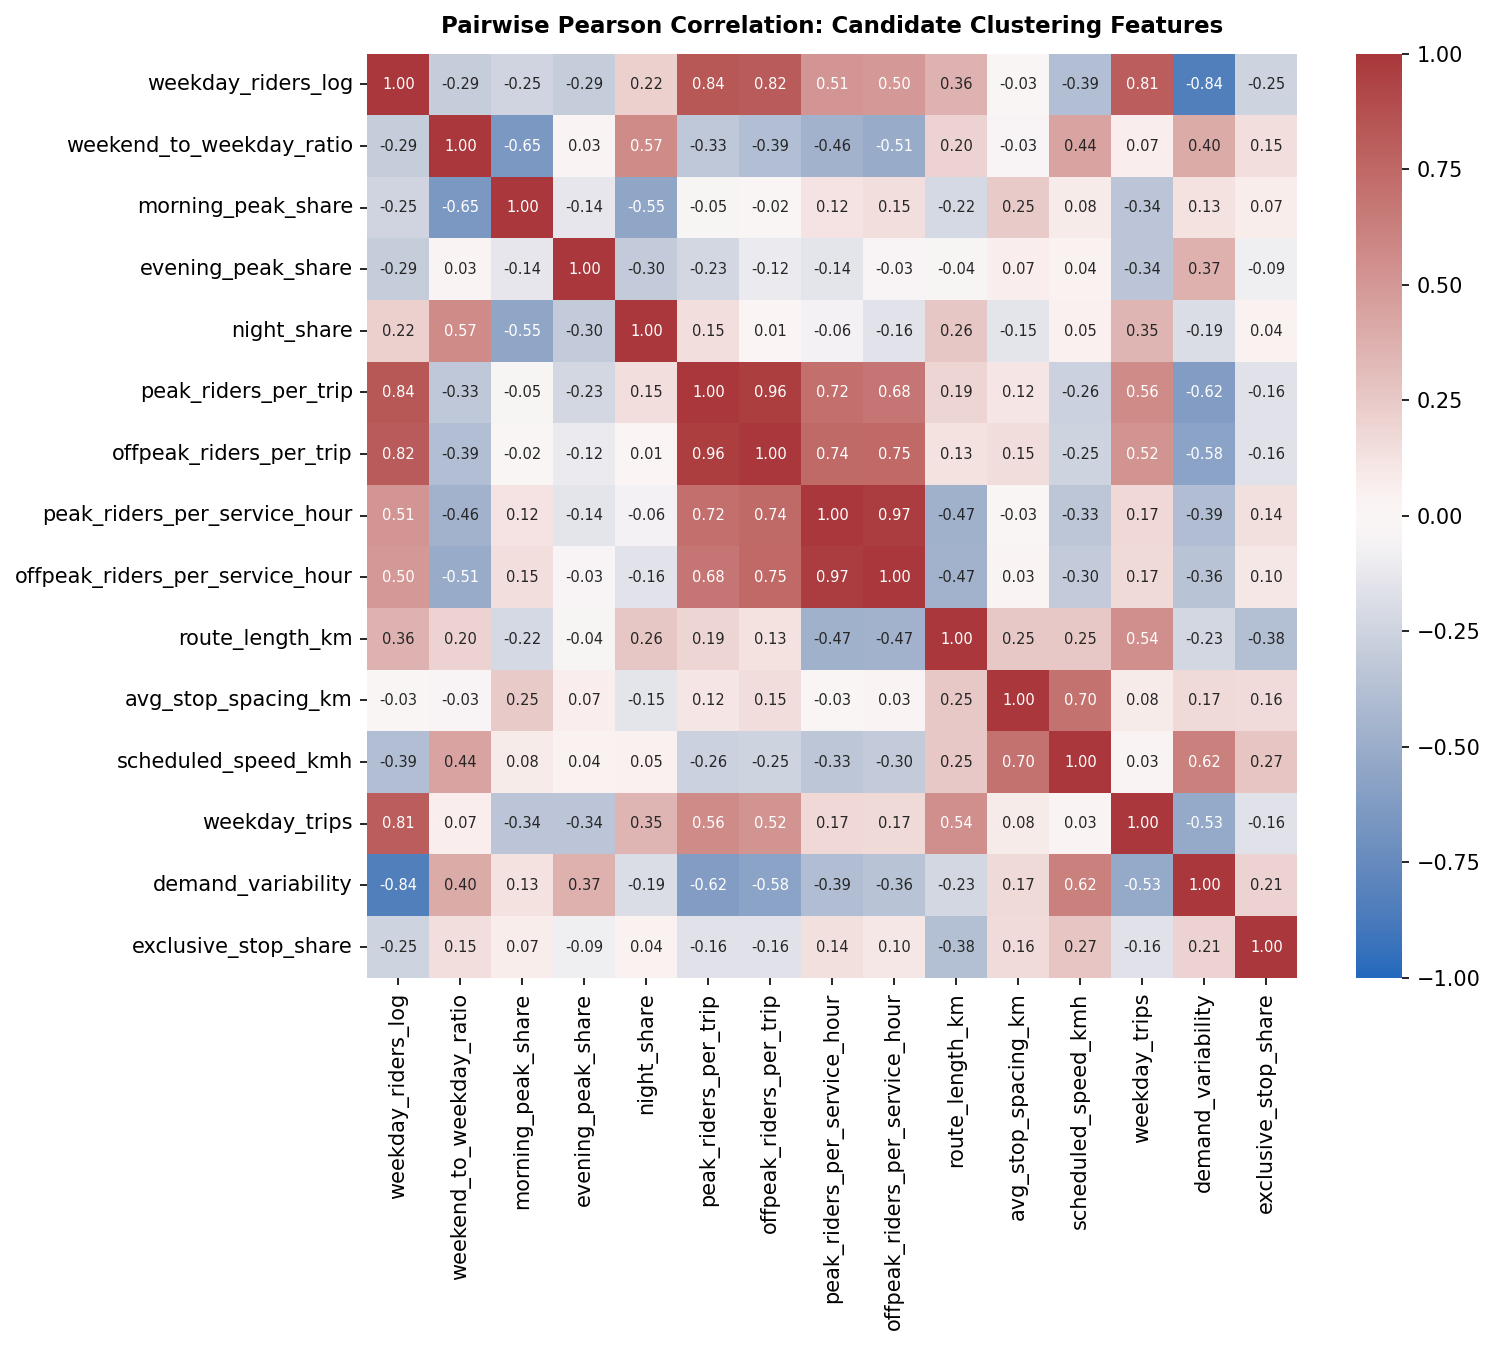

In [2]:
corr_matrix = pd.read_csv(TAB / 'm2_clustering_feature_correlations.csv', index_col=0)
print('Correlation Matrix for Candidate Route Metrics:')

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
sns.heatmap(corr_matrix, cmap='vlag', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Pairwise Pearson Correlation: Candidate Clustering Features', fontsize=11, fontweight='bold', pad=10)
fig.savefig(FIG / 'm2_clustering_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 13.2: Selected 9 Scaled Clustering Features
The final 9 features cover volume scale, weekend orientation, peak concentration, night service, operational efficiency, length, speed, stability, and network exclusivity (maximum pairwise $|r| = 0.840 < 0.85$).

In [3]:
cf_scaled = pd.read_parquet(DATA / 'clustering_features.parquet')
print(f'Total routes: {len(cf_scaled)} (41 routes)')
print('\nScaled Features Sample (Ready for K-Means / Hierarchical Clustering in Milestone 3):')
cf_scaled.head(15)

Total routes: 41 (41 routes)

Scaled Features Sample (Ready for K-Means / Hierarchical Clustering in Milestone 3):


,route,weekday_riders_log,weekend_to_weekday_ratio,morning_peak_share,night_share,peak_riders_per_service_hour,route_length_km,scheduled_speed_kmh,demand_variability,exclusive_stop_share
0,M1,0.579442,-0.093460,-0.504577,-1.302694,-0.758185,1.201827,-0.241185,-0.338681,-0.975944
1,M10,-0.431804,0.790246,-1.062098,-0.038117,-1.005210,0.050665,-0.282388,-0.009658,1.384052
2,M101,1.100410,-0.105528,-0.160278,1.067916,-0.647248,1.982972,0.418054,-0.598262,-0.967157
3,M102,0.602458,0.150240,-0.422435,0.898048,-0.464001,0.929183,-0.158780,-0.156809,-1.935684
4,M103,0.459179,0.515012,-0.899560,0.837650,-0.514753,0.989771,-0.488400,0.085411,-1.281594
5,M104,0.139964,1.798915,-1.726228,0.875398,-0.560116,0.037682,-0.570805,-0.256012,0.058679
6,M106,-1.073967,-1.338823,0.572013,-2.752239,-0.029687,-0.903587,-0.405995,2.076081,-0.613368
7,M11,0.667255,-0.017158,-0.268636,0.022281,-0.139276,0.868596,-0.282388,-0.549487,0.264992
8,M116,0.041369,-0.275651,0.433944,-0.581696,0.026455,-0.819197,-0.282388,-0.474258,-0.729132
9,M12,-1.438592,0.832290,-0.188241,0.614933,-0.260992,-0.557373,0.253244,0.490489,0.194311


## Step 13.3: Unscaled Route Profiles (Natural Units)
Natural units table for interpreting cluster centroids and business profiles.

In [4]:
cf_unscaled = pd.read_csv(TAB / 'm2_clustering_features_unscaled.csv')
selected_cols = ['route'] + [c for c in cf_scaled.columns if c != 'route']
cf_unscaled[selected_cols].head(15)

,route,weekday_riders_log,weekend_to_weekday_ratio,morning_peak_share,night_share,peak_riders_per_service_hour,route_length_km,scheduled_speed_kmh,demand_variability,exclusive_stop_share
0,M1,8.9478,0.6088,0.2131,0.0853,29.94,13.68,9.8,0.1754,0.2687
1,M10,7.9724,0.8358,0.1812,0.1188,24.44,8.36,9.7,0.2152,0.8864
2,M101,9.4503,0.6057,0.2328,0.1481,32.41,17.29,11.4,0.1440,0.2710
3,M102,8.9700,0.6714,0.2178,0.1436,36.49,12.42,10.0,0.1974,0.0175
4,M103,8.8318,0.7651,0.1905,0.1420,35.36,12.70,9.2,0.2267,0.1887
5,M104,8.5239,1.0949,0.1432,0.1430,34.35,8.30,9.0,0.1854,0.5395
6,M106,7.3530,0.2889,0.2747,0.0469,46.16,3.95,9.4,0.4675,0.3636
7,M11,9.0325,0.6284,0.2266,0.1204,43.72,12.14,9.7,0.1499,0.5935
8,M116,8.4288,0.5620,0.2668,0.1044,47.41,4.34,9.7,0.1590,0.3333
9,M12,7.0013,0.8466,0.2312,0.1361,41.01,5.55,11.0,0.2757,0.5750
